# Paper figures (revised paper)

Figures of the revised manuscript (`artigo/confocal_paper.tex`), written to `data/gold_layer/paper_figures/` (copy them to `artigo/figures/paper_figures/`).

* **Final size and fonts**: every figure is produced at its final width in the paper (one column: 252 pt; two columns: 522 pt, `elsarticle` 5p) with the fonts of the paper (Times, `txfonts`): 8 pt labels, 7 pt ticks and legends. Figures are saved without cropping, so they are included in LaTeX at their natural size (scale 1).
* **Data**: silver layer `confocal_runs_processed_v2` (profiles, KDEs) and the results of the criterion version reported in the paper (`CRITERIA_VERSION`, currently **`objective_criteria_6`**, `processed_v2`). The criterion is **not** re-run here: the criterion figures are re-plotted from its `processed_v2/*.csv` files, so the classification is exactly the one of that version (checked at the end).
* **Runs**: the 157 runs of the paper ($j_l \geq 0.035$ m/s), 7 reference classes (visual stratified evaluated as wavy).

| File | Content | Width |
|---|---|---|
| `fig06_tube_thickness_before_treatment.pdf`, `fig07_tube_thickness_after_treatment.pdf` | $\delta_1$ per pattern before / after the treatment | column |
| `fig08a_mixer_wave_before.pdf`, `fig08b_mixer_wave_after.pdf` | wavy profile before / after the mixer-wave removal | column |
| `fig09_evaluated_region.pdf` | experimental region on the Coleman and Garimella map | column |
| `fig11_decision_tree.tex` / `.pdf` | decision tree (TikZ, `\input` in the paper) | text |
| `fig12a_...` to `fig17c_...` | film profiles | column |
| `fig18a_bottom_film_by_pattern.pdf`, `fig18b_bottom_film_separated_zoom.pdf` | mean bottom film per pattern | column |
| `fig19a_kde_bubbly.pdf` to `fig19f_kde_wavy.pdf` | PDF of the detected $\delta_2$ per pattern (x label on (e), (f) only) | column |
| `fig20a_...`, `fig20b_...`, `fig21a_...` to `fig21d_...` | feature planes of the criterion (legend inside) | column |
| `fig22_confusion_matrix.pdf` | confusion matrix | column |
| `fig23a_flow_pattern_map_visual.pdf`, `fig23b_flow_pattern_map_objective.pdf` | visual and objective maps | column |
| `fig24_sensitivity_thresholds.pdf` | threshold sensitivity | text |

In [1]:
import json
import shutil
import subprocess
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.append(str(project_root))

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
import seaborn as sns
from matplotlib.ticker import MaxNLocator

from IPython.display import display

from src.boxplots import boxplot_plot
from src.plot_flow_pattern_maps import map_garimella, map_garimella_region
from src.flow_pattern_criteria import (
    load_run,
    film_estimate,
    balanced_accuracy,
    reference_pattern,
    JL_MIN,
    OBJECTIVE_PATTERNS,
)
from src.flow_pattern_report import (
    pattern_styles,
    criterion_scatter,
    confusion_heatmap,
    sweep_figure,
    VISUAL_PATTERNS,
    _densest_window,
)

In [2]:
# =========================================================
# Paper layout (elsarticle 5p, two columns) and fonts (Times, txfonts)
# =========================================================

PT = 1 / 72.27            # TeX point in inches
COL_W = 252.0 * PT        # \columnwidth
TEXT_W = 522.0 * PT       # \textwidth
CM = 1 / 2.54
COL_CM = COL_W / CM

PAPER_RC = {
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],   # no font package from matplotlib; txfonts sets Times
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.5,
    "ytick.minor.size": 1.5,
    "lines.linewidth": 0.8,
    "grid.linewidth": 0.4,
    "ytick.color": "black",
    "xtick.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
}

plt.rcParams.update(PAPER_RC)

# Flow pattern maps: ticks inside (as in flow_pattern_maps.ipynb)
MAP_RC = {"xtick.direction": "in", "ytick.direction": "in"}

# Heights [in]
PROFILE_H = 1.2
PROFILE_LEGEND_H = 1.45
BOX_H = 2.35
SCATTER_H = 2.2
MAP_H = 2.4

## Data

All results come from `CRITERIA_VERSION` (`processed_v2`). The pattern order and the box colours are the same in every figure.

In [3]:
silver_root = project_root / 'data/silver_layer'
gold_root = project_root / 'data/gold_layer'

CRITERIA_VERSION = 'objective_criteria_11'   # version reported in the paper (v10 with dimensionless length thresholds)
criteria_path = gold_root / CRITERIA_VERSION
results_path = criteria_path / 'processed_v2'

# Figures are written inside the criterion version folder, so they are traceable to its
# run_manifest.json; each run creates the next free paper_figures_<N> folder and never
# overwrites a previous set of figures
from src.output_versions import next_version_dir
out = next_version_dir(criteria_path, 'paper_figures')
print('Output folder:', out)

RUNS = {
    'regular': silver_root / 'confocal_runs',
    'processed': silver_root / 'confocal_runs_processed',
    'processed_v2': silver_root / 'confocal_runs_processed_v2',
}

manifest = json.loads((criteria_path / 'run_manifest.json').read_text())
P = manifest['criterion_params']
F = manifest['feature_params']

df_experimental = pd.read_pickle(silver_root / 'experimental_results.pkl')

# Features and objective pattern of the 157 runs (reduced_pattern = reference class)
features = pd.read_csv(results_path / 'objective_flow_pattern.csv', index_col=0)

# Runs of the paper with the reference classes (visual stratified -> wavy)
df_eval = df_experimental[df_experimental['jl'] >= JL_MIN].copy()
df_eval['visual_pattern'] = df_eval['reduced_pattern']
df_eval['reduced_pattern'] = reference_pattern(df_eval['reduced_pattern'])
eval_rows = df_eval.set_index('run_id')

assert len(df_eval) == len(features) == 157

# Pattern order and colours used in every figure
PATTERNS = [p for p in VISUAL_PATTERNS if p != 'stratified']
BOX_COLORS = dict(zip(PATTERNS, ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#937860', '#8C8C8C']))

# Marker / colour per pattern, as in the flow pattern maps and the criterion figures of kde_plots.ipynb
map_categories = list(df_experimental['reduced_pattern'].unique())
styles = pattern_styles(map_categories)

saved = []


def save(fig, name, rc=None):
    """
    Save at the figure size (no cropping), after a tight layout, so the PDF has
    exactly the width of the paper column or text.
    """
    dpi = fig.dpi
    with plt.rc_context(rc or {}):
        # Layout at a fixed resolution, twice, so that the label positions settle
        fig.set_dpi(300)
        for _ in range(2):
            fig.tight_layout(pad=0.3)
            fig.canvas.draw()
        # Check that nothing is drawn outside the figure
        width, height = fig.get_size_inches()
        bbox = fig.get_tightbbox(fig.canvas.get_renderer())
        assert bbox.x0 >= 0 and bbox.y0 >= 0 and bbox.x1 <= width and bbox.y1 <= height, (name, bbox)
        path = out / f'{name}.pdf'
        fig.savefig(path, format='pdf')
    fig.set_dpi(dpi)
    saved.append(path.name)
    return fig


df_eval['reduced_pattern'].value_counts().loc[PATTERNS]

Output folder: C:\Users\fernando\Downloads\projects\phd_paper\data\gold_layer\objective_criteria_11\paper_figures_1


reduced_pattern
bubbly       11
plug         33
slug         25
dispersed    20
churn        14
wavy         44
annular      10
Name: count, dtype: int64

## Data treatment

**Figs. 6 and 7**: mean first thickness $\delta_1$ per pattern before (raw data) and after (processed\_v2) the treatment.

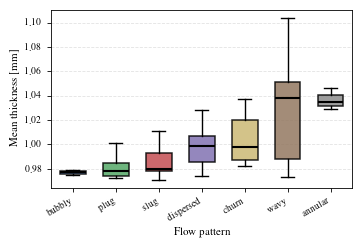

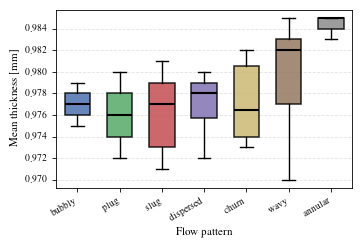

In [4]:
results = {
    'regular': pd.read_pickle(silver_root / 'confocal_results.pkl'),
    'processed_v2': pd.read_pickle(silver_root / 'confocal_results_processed_v2.pkl'),
}

for variant, name in [
    ('regular', 'fig06_tube_thickness_before_treatment'),
    ('processed_v2', 'fig07_tube_thickness_after_treatment'),
]:

    df = df_eval.merge(results[variant], on='run_id')

    fig, ax = boxplot_plot(
        df, 't1_mean', 'Mean thickness', 'mm',
        FIG_WIDTH_CM=COL_CM, FIG_HEIGHT_CM=BOX_H / CM,
        patterns=PATTERNS, colors=[BOX_COLORS[p] for p in PATTERNS], rotation=30,
    )

    save(fig, name)
    display(fig)

**Fig. 8**: wavy flow profile (run 46, 1.34 kHz) before (a) and after (b) the mixer-wave removal, in the style of the other profiles; the removed samples are marked in red in (a).

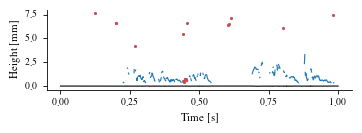

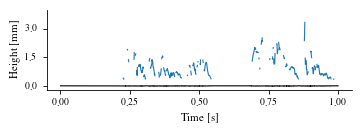

In [5]:
GLASS_THICKNESS = 0.96
INTERFACE_COLOR = '#1f77b4'
T1_FILM_COLOR = '#DD8452'
REMOVED_COLOR = '#C44E52'


def profile_axes(height=PROFILE_H, width=COL_W):
    fig, ax = plt.subplots(figsize=(width, height))
    return fig, ax


def finish_profile(ax):
    ax.set_xlabel('Time [s]')
    ax.set_ylabel('Height [mm]')
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def window(df, t_start, t_max):
    df = df[(df['time'] >= t_start) & (df['time'] <= t_start + t_max)].copy()
    df['time'] = df['time'] - t_start
    return df


def profile_figure(df, t_start=0.0, t_max=1.0, film_from_t1=False, width=COL_W, legend=True):
    """
    Film profile: inner wall (first thickness minus the glass thickness, black)
    and detected interface (blue). With ``film_from_t1`` the film below the
    detection limit (bottom film estimate, needs ``t1_raw``) is added as dots.
    """

    df = window(df, t_start, t_max)
    fig, ax = profile_axes(PROFILE_LEGEND_H if film_from_t1 and legend else PROFILE_H, width=width)

    ax.plot(df['time'].to_numpy(), (df['t1'] - GLASS_THICKNESS).to_numpy(), color='black')
    ax.plot(df['time'].to_numpy(), df['t2'].to_numpy(), color=INTERFACE_COLOR, label=r'detected $\delta_2$')

    if film_from_t1:
        estimate = film_estimate(df)
        merged = df['t2'].isna().to_numpy() & ~np.isnan(estimate)
        ax.plot(df['time'].to_numpy()[merged], estimate[merged], '.', color=T1_FILM_COLOR, markersize=1.5,
                label=r'estimate from $\delta_1$ (below detection)')
        if legend:
            ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2,
                      markerscale=3, handlelength=1.5, borderaxespad=0.1)

    finish_profile(ax)
    plt.close(fig)
    return fig


# Fig. 8: run 46, first second of the record
before = window(load_run(46, RUNS['processed']), 0.0, 1.0)
after = window(load_run(46, RUNS['processed_v2']), 0.0, 1.0)
removed = after['mixer_wave'].astype(bool).to_numpy()

fig, ax = profile_axes()
ax.plot(before['time'].to_numpy(), (before['t1'] - GLASS_THICKNESS).to_numpy(), color='black')
ax.plot(before['time'].to_numpy(), before['t2'].to_numpy(), color=INTERFACE_COLOR)
ax.plot(before['time'].to_numpy()[removed], before['t2'].to_numpy()[removed], '.', color=REMOVED_COLOR, markersize=2.5)
finish_profile(ax)
plt.close(fig)
save(fig, 'fig08a_mixer_wave_before')
display(fig)

fig = profile_figure(load_run(46, RUNS['processed_v2']), t_max=1.0)
save(fig, 'fig08b_mixer_wave_after')
display(fig)

## Experimental range

**Fig. 9**: region of the 157 runs on the Coleman and Garimella map.

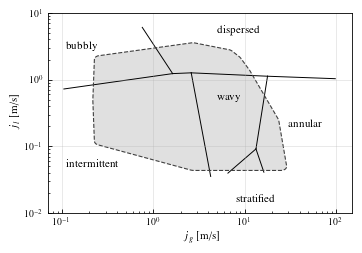

In [6]:
with plt.rc_context(MAP_RC):

    fig, ax = map_garimella_region(
        df_experimental[df_experimental['jl'] >= JL_MIN], label='',
        FIG_WIDTH_CM=COL_CM, FIG_HEIGHT_CM=MAP_H / CM,
    )

    save(fig, 'fig09_evaluated_region', rc=MAP_RC)
    display(fig)

## Objective criterion

**Fig. 11**: decision tree, written as a TikZ file (`fig11_decision_tree.tex`, to `\input` in the paper) with the thresholds of `CRITERIA_VERSION`, in the notation of the paper. A standalone PDF is compiled when `pdflatex` is available.

In [7]:
TREE_TEX = r"""\begin{tikzpicture}[
    dec/.style={draw, rounded corners=2pt, align=center, font=\footnotesize, inner sep=3pt, text width=3.6cm},
    result/.style={draw, align=center, font=\footnotesize\bfseries, minimum width=1.5cm, minimum height=0.55cm},
    arr/.style={-{Stealth[length=1.6mm]}, semithick},
    lab/.style={font=\scriptsize, fill=white, inner sep=1pt},
]

% Start and family test
\node[dec, text width=5.4cm] (start) at (0, 0) {Confocal record\\ + mean $(dp/dz)_{tp}$ of the run};
\node[dec, text width=5.4cm] (bridge) at (0, -1.45) {Liquid bridges\\ ($\delta_2/D_h \geq <H_LIQ>$ for $\geq <DWELL>$~ms)\\ $f_{bridge} \geq <F_BRIDGE>$~Hz?};

% Intermittent family
\node[dec, text width=3.0cm] (bub) at (-4.0, -2.9) {$S_b \geq <BUBBLE>$?};
\node[result] (bubbly) at (-5.5, -4.4) {Bubbly};
\node[dec, text width=3.2cm] (plugq) at (-2.6, -4.4) {$\bar t_{bridge} \geq <PLUG_MS>$~ms\\ and $f_{liquid} \geq <PLUG_FL>$?};
\node[result] (plug) at (-3.6, -5.9) {Plug};
\node[result] (slug) at (-1.6, -5.9) {Slug};

% Separated family
\node[dec, text width=3.9cm] (ann) at (3.4, -2.9) {Bottom film\\ $\bar\delta_f/D_h < <ANN_MEAN>$ and $\sigma_f/D_h < <ANN_STD>$?};
\node[result] (annular) at (7.3, -2.9) {Annular};
\node[dec, text width=3.9cm] (agit) at (3.4, -4.95) {Agitated film?\\ $N_p \geq <PEAKS>$, or\\ ($\bar\delta_f/D_h \geq <DISP_MEAN>$, $J \geq <DISP_JUMP>$, $\delta_2$ detected in $\geq <DISP_DET>\,\%$)\\ and $R_h \geq <HOMOG>$};
\node[dec, text width=3.9cm] (liq) at (3.4, -7.35) {Liquid-rich film?\\ $\bar\delta_f/D_h < <LR_FILM>$,\\ $R_h \geq <HOMOG>$\\ and $\phi_l^2 \leq <LR_PHI2>$};
\node[result] (wavy) at (3.4, -9.0) {Wavy};
\node[dec, text width=2.6cm] (split) at (7.3, -6.15) {$N_p \geq <PEAKS>$\\ or $\phi_l^2 \leq <DISP_PHI2>$?};
\node[result] (churn) at (6.35, -7.75) {Churn};
\node[result] (dispersed) at (8.25, -7.75) {Dispersed};

% Arrows
\draw[arr] (start) -- (bridge);
\draw[arr] (bridge.west) -| node[lab, pos=0.72] {yes: intermittent} (bub.north);
\draw[arr] (bridge.east) -| node[lab, pos=0.72] {no: separated} (ann.north);

\draw[arr] ([xshift=-6mm]bub.south) -- node[lab] {yes} (bubbly.north);
\draw[arr] ([xshift=6mm]bub.south) -- node[lab] {no} (plugq.north);
\draw[arr] ([xshift=-5mm]plugq.south) -- node[lab] {yes} (plug.north);
\draw[arr] ([xshift=5mm]plugq.south) -- node[lab] {no} (slug.north);

\draw[arr] (ann.east) -- node[lab] {yes} (annular.west);
\draw[arr] (ann.south) -- node[lab] {no} (agit.north);
\draw[arr] (agit.south) -- node[lab] {no} (liq.north);
\draw[arr] (liq.south) -- node[lab] {no} (wavy.north);
\draw[arr] (agit.east) -- node[lab, above, sloped] {yes} (split.north west);
\draw[arr] (liq.east) -- node[lab, below, sloped] {yes} (split.south west);
\draw[arr] ([xshift=-4mm]split.south) -- node[lab] {no} (churn.north);
\draw[arr] ([xshift=4mm]split.south) -- node[lab] {yes} (dispersed.north);

\end{tikzpicture}
"""

STANDALONE = r"""\documentclass[border=2pt]{standalone}
\usepackage{amsmath}
\usepackage{txfonts}
\usepackage{tikz}
\usetikzlibrary{arrows.meta, positioning}
\begin{document}
\input{fig11_decision_tree}
\end{document}
"""

thresholds = {
    '<H_LIQ>': f"{F['h_liq_rel']:g}",
    '<DWELL>': f"{1000 * F['min_dwell']:g}",
    '<F_BRIDGE>': f"{P['f_bridge_hz']:g}",
    '<BUBBLE>': f"{P['bubble_share_min']:g}",
    '<PLUG_MS>': f"{1000 * P['plug_min_duration']:g}",
    '<PLUG_FL>': f"{P['plug_min_f_liquid']:.2f}",
    '<ANN_MEAN>': f"{P['annular_max_mean_rel']:g}",
    '<ANN_STD>': f"{P['annular_max_std_rel']:g}",
    '<PEAKS>': f"{P['dispersed_min_peaks']:g}",
    '<DISP_MEAN>': f"{P['dispersed_min_mean_rel']:g}",
    '<DISP_JUMP>': f"{P['dispersed_min_jump']:g}",
    '<DISP_DET>': f"{100 * P['dispersed_min_detected']:g}",
    '<HOMOG>': f"{P['agitated_min_homog_ratio']:g}",
    '<DISP_PHI2>': f"{P['dispersed_max_phi2']:g}",
    '<LR_FILM>': f"{P['liquid_rich_max_film_rel']:g}",
    '<LR_PHI2>': f"{P['liquid_rich_max_phi2']:g}",
}

tex = TREE_TEX

for key, value in thresholds.items():
    tex = tex.replace(key, value)

tex_path = out / 'fig11_decision_tree.tex'
tex_path.write_text(tex, encoding='utf-8')
saved.append(tex_path.name)

if shutil.which('pdflatex'):

    build = out / '_build'
    build.mkdir(exist_ok=True)
    shutil.copy(tex_path, build / tex_path.name)
    (build / 'tree_standalone.tex').write_text(STANDALONE, encoding='utf-8')

    subprocess.run(
        ['pdflatex', '-interaction=nonstopmode', '-halt-on-error', 'tree_standalone.tex'],
        check=True, capture_output=True, timeout=300, cwd=build,
    )

    shutil.copy(build / 'tree_standalone.pdf', out / 'fig11_decision_tree.pdf')
    shutil.rmtree(build)
    saved.append('fig11_decision_tree.pdf')

thresholds

{'<H_LIQ>': '0.9375',
 '<DWELL>': '5',
 '<F_BRIDGE>': '0.1',
 '<BUBBLE>': '0.5',
 '<PLUG_MS>': '20',
 '<PLUG_FL>': '0.10',
 '<ANN_MEAN>': '0.0125',
 '<ANN_STD>': '0.025',
 '<PEAKS>': '2',
 '<DISP_MEAN>': '0.05',
 '<DISP_JUMP>': '0.4',
 '<DISP_DET>': '15',
 '<HOMOG>': '1',
 '<DISP_PHI2>': '5.5',
 '<LR_FILM>': '0.0625',
 '<LR_PHI2>': '20'}

## Film thickness profiles

**Figs. 12-16**: same runs and windows as the current paper (0.5 s for bubbly, 1 s otherwise), from processed\_v2. **Fig. 17**: churn and annular profiles, with the film below the detection limit recovered from $\delta_1$ (orange), in the 1 s window with the most detected samples.

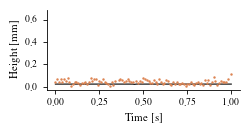

In [8]:
# (file name, run, window [s])
PROFILE_RUNS = [
    ('fig12a_profile_bubbly_run65', 65, 0.5),
    ('fig12b_profile_bubbly_run59', 59, 0.5),
    ('fig13a_profile_plug_run33', 33, 1.0),
    ('fig13b_profile_plug_run28', 28, 1.0),
    ('fig14a_profile_slug_run67', 67, 1.0),
    ('fig14b_profile_slug_run56', 56, 1.0),
    ('fig15a_profile_dispersed_run8', 8, 1.0),
    ('fig15b_profile_dispersed_run9', 9, 1.0),
    ('fig16a_profile_wavy_run45', 45, 1.0),
    ('fig16b_profile_wavy_run44', 44, 1.0),
]

for name, run_id, t_max in PROFILE_RUNS:
    fig = profile_figure(load_run(run_id, RUNS['processed_v2']), t_max=t_max)
    save(fig, name)

# Fig. 17: churn and annular profiles with the film recovered from the first thickness
CHURN_ANNULAR_RUNS = [
    ('fig17a_profile_churn_run93', 93),
    ('fig17b_profile_churn_liquid_rich_run1', 1),
    ('fig17c_profile_annular_run85', 85),
]

# Three panels side by side at a third of the text width (figure* in the paper); the colours
# (blue: detected delta_2, orange: estimate from delta_1) are given in the caption
THIRD_W = (TEXT_W - 0.12) / 3

for name, run_id in CHURN_ANNULAR_RUNS:
    df_run = load_run(run_id, RUNS['processed_v2'], raw_path=RUNS['regular'])
    fig = profile_figure(df_run, t_start=_densest_window(df_run, 1.0), t_max=1.0, film_from_t1=True,
                         width=THIRD_W, legend=False)
    save(fig, name)

display(fig)

## Mean bottom film by pattern

**Fig. 18a**: mean bottom film estimate per pattern. **Fig. 18b**: zoom on the separated patterns, same colours.

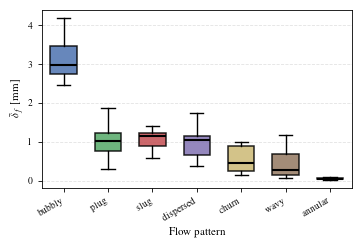

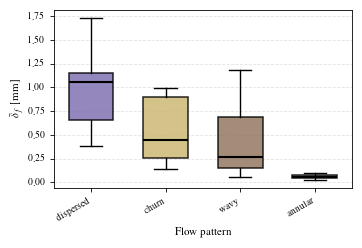

In [9]:
fig, ax = boxplot_plot(
    features, 'film_est_mean_mm', r'$\bar\delta_f$', 'mm',
    FIG_WIDTH_CM=COL_CM, FIG_HEIGHT_CM=BOX_H / CM,
    patterns=PATTERNS, colors=[BOX_COLORS[p] for p in PATTERNS], rotation=30,
)
save(fig, 'fig18a_bottom_film_by_pattern')
display(fig)

separated = ['dispersed', 'churn', 'wavy', 'annular']

fig, ax = boxplot_plot(
    features, 'film_est_mean_mm', r'$\bar\delta_f$', 'mm',
    FIG_WIDTH_CM=COL_CM, FIG_HEIGHT_CM=BOX_H / CM,
    patterns=separated, colors=[BOX_COLORS[p] for p in separated], rotation=30,
)
save(fig, 'fig18b_bottom_film_separated_zoom')
display(fig)

## PDF of the detected second thickness

**Fig. 19 (a)-(f)**: KDE (Gaussian, Scott bandwidth) of the detected $\delta_2$, six runs per pattern, one column-width panel per pattern (combined in the paper with the panel letters below each panel); x label only on the bottom row.

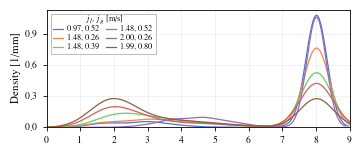

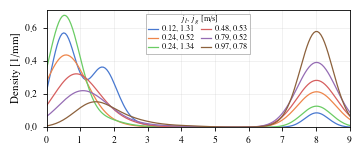

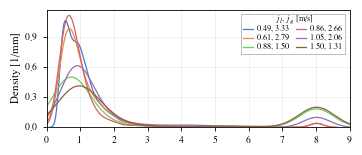

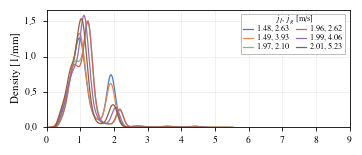

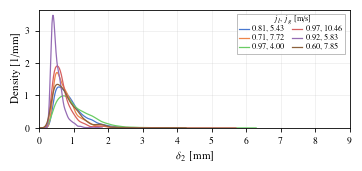

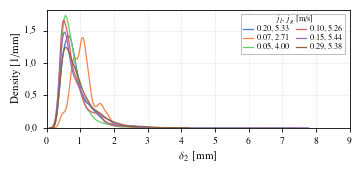

In [10]:
KDE_RUNS = {
    'bubbly': [65, 61, 60, 59, 50, 53],
    'plug': [35, 33, 36, 31, 28, 66],
    'slug': [15, 14, 13, 25, 87, 56],
    'dispersed': [81, 80, 74, 75, 76, 77],
    'churn': [26, 27, 94, 138, 1, 140],
    'wavy': [45, 41, 148, 47, 46, 44],
}

for pattern, run_ids in KDE_RUNS.items():
    assert (eval_rows.loc[run_ids, 'reduced_pattern'] == pattern).all(), pattern


def kde_axes(ax, run_ids, xlabel=True):

    palette = sns.color_palette('muted', len(run_ids))

    for color, run_id in zip(palette, run_ids):
        t2 = load_run(run_id, RUNS['processed_v2'])['t2'].dropna()
        row = eval_rows.loc[run_id]
        sns.kdeplot(x=t2, ax=ax, color=color, linewidth=0.9, label=f"{row['jl']:.2f}, {row['jg']:.2f}", zorder=2)

    ax.set_xlim(0, 9)
    ax.set_xlabel(r'$\delta_2$ [mm]' if xlabel else '')
    ax.set_ylabel('Density [1/mm]')
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.grid(alpha=0.3, zorder=0)
    legend = ax.legend(title=r'$j_l$, $j_g$ [m/s]', loc='best', frameon=True, framealpha=0.9, edgecolor='0.6',
                       fancybox=False, fontsize=6, title_fontsize=6, labelspacing=0.15, handlelength=1.2,
                       handletextpad=0.4, borderpad=0.3, ncol=2, columnspacing=0.8)
    legend.get_frame().set_linewidth(0.5)


# Panels (a)-(f) of Fig. 19: the bottom row carries the x label, so it is taller by the label height
KDE_H = 1.42
KDE_LABEL_H = 0.16

for letter, (pattern, run_ids) in zip('abcdef', KDE_RUNS.items()):
    bottom = letter in 'ef'
    fig, ax = plt.subplots(figsize=(COL_W, KDE_H + (KDE_LABEL_H if bottom else 0)))
    kde_axes(ax, run_ids, xlabel=bottom)
    plt.close(fig)
    save(fig, f'fig19{letter}_kde_{pattern}')
    display(fig)

## Feature planes of the criterion

Re-plotted from the features of `CRITERIA_VERSION` at column width, with the legend inside the axes. No run identifiers are drawn.

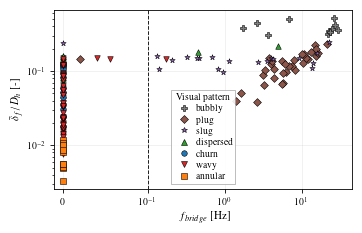

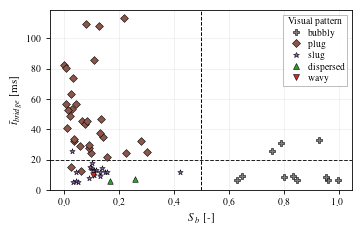

In [11]:
SCATTER = dict(figsize=(COL_W, SCATTER_H), legend_loc='best')

# Fig. 20a: family (intermittent vs. separated)
fig = criterion_scatter(
    features, 'bridge_freq_hz', 'film_est_mean_rel',
    r'$f_{bridge}$ [Hz]', r'$\bar\delta_f/D_h$ [-]', styles,
    xlines=[P['f_bridge_hz']],
    xscale='symlog',
    yscale='log',
    **{**SCATTER, 'legend_loc': 'lower center'},
)
save(fig, 'fig20a_criterion_family')
display(fig)

# Fig. 20b: intermittent family
df_intermittent = features[features['bridge_freq_hz'] >= P['f_bridge_hz']].copy()
df_intermittent['bridge_mean_duration_ms'] = 1000 * df_intermittent['bridge_mean_duration_s']

fig = criterion_scatter(
    df_intermittent, 'bubble_share', 'bridge_mean_duration_ms',
    r'$S_b$ [-]', r'$\bar t_{bridge}$ [ms]', styles,
    xlines=[P['bubble_share_min']],
    ylines=[1000 * P['plug_min_duration']],
    **SCATTER,
)
save(fig, 'fig20b_criterion_intermittent')
display(fig)

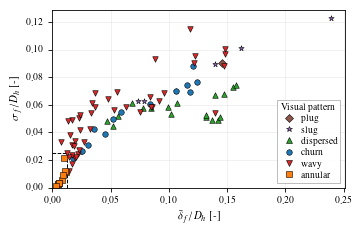

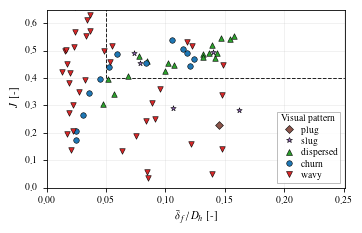

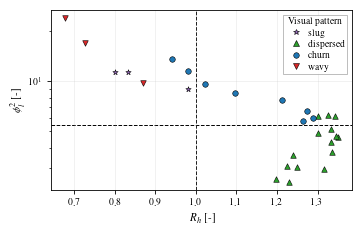

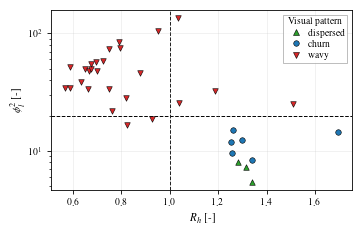

In [12]:
df_separated = features[features['bridge_freq_hz'] < P['f_bridge_hz']]

# Fig. 21a: annular box (mean vs. std of the bottom film)
mean_a, std_a = P['annular_max_mean_rel'], P['annular_max_std_rel']

fig = criterion_scatter(
    df_separated, 'film_est_mean_rel', 'film_est_std_rel',
    r'$\bar\delta_f/D_h$ [-]', r'$\sigma_f/D_h$ [-]', styles,
    segments=[((mean_a, mean_a), (0, std_a)), ((0, mean_a), (std_a, std_a))],
    xlim=(0, 1.05 * df_separated['film_est_mean_rel'].max()),
    ylim=(0, 1.05 * df_separated['film_est_std_rel'].max()),
    **SCATTER,
)
save(fig, 'fig21a_criterion_separated')
display(fig)

# Fig. 21b: thick and jumpy film (non-annular separated runs)
df_film = df_separated[df_separated['objective_pattern'] != 'annular']
mean_d, jump_d = P['dispersed_min_mean_rel'], P['dispersed_min_jump']
x_max = 1.05 * df_film['film_est_mean_rel'].max()

fig = criterion_scatter(
    df_film, 'film_est_mean_rel', 'film_jump_frac',
    r'$\bar\delta_f/D_h$ [-]', r'$J$ [-]', styles,
    segments=[((mean_d, mean_d), (jump_d, 1.0)), ((mean_d, x_max), (jump_d, jump_d))],
    xlim=(0, x_max),
    ylim=(0, 0.65),
    **SCATTER,
)
save(fig, 'fig21b_criterion_dispersed')
display(fig)

# Fig. 21c: pressure gate and dispersed / churn split (agitated films)
agitated_signature = (
    (features['n_peaks'] >= P['dispersed_min_peaks'])
    | (
        (features['film_est_mean_rel'] >= P['dispersed_min_mean_rel'])
        & (features['film_jump_frac'] >= P['dispersed_min_jump'])
        & (1 - features['f_undetected'] >= P['dispersed_min_detected'])
    )
)
df_agitated = features[agitated_signature & (features['bridge_freq_hz'] < P['f_bridge_hz'])]

fig = criterion_scatter(
    df_agitated, 'ratio_homog', 'phi2_l',
    r'$R_h$ [-]', r'$\phi_l^2$ [-]', styles,
    xlines=[P['agitated_min_homog_ratio']],
    ylines=[P['dispersed_max_phi2']],
    yscale='log',
    **SCATTER,
)
save(fig, 'fig21c_criterion_agitated')
display(fig)

# Fig. 21d: liquid-rich branch (separated, neither annular nor agitated, thin film seen)
annular_film = (
    (features['film_est_mean_rel'].fillna(0) < P['annular_max_mean_rel'])
    & (features['film_est_std_rel'].fillna(0) < P['annular_max_std_rel'])
)

df_thin = features[
    (features['bridge_freq_hz'] < P['f_bridge_hz'])
    & ~annular_film
    & ~agitated_signature
    & (features['film_est_mean_rel'] < P['liquid_rich_max_film_rel'])
]

fig = criterion_scatter(
    df_thin, 'ratio_homog', 'phi2_l',
    r'$R_h$ [-]', r'$\phi_l^2$ [-]', styles,
    xlines=[P['agitated_min_homog_ratio']],
    ylines=[P['liquid_rich_max_phi2']],
    yscale='log',
    **SCATTER,
)
save(fig, 'fig21d_criterion_liquid_rich')
display(fig)

## Agreement with the visual classification

**Fig. 22**: confusion matrix (same pattern order on both axes). **Fig. 23**: visual and objective maps, same markers; the region labels are drawn above the markers with a white outline.

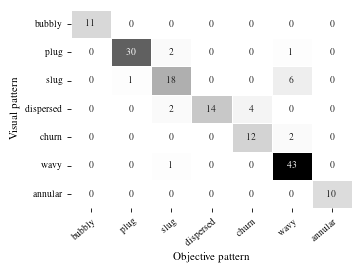

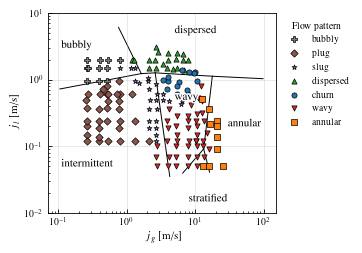

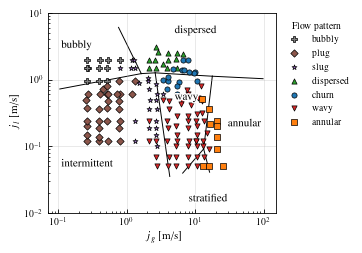

In [13]:
confusion = pd.crosstab(features['reduced_pattern'], features['objective_pattern']).reindex(
    index=PATTERNS, columns=PATTERNS, fill_value=0
)

# Same counts as the confusion matrix of CRITERIA_VERSION
reference = pd.read_csv(results_path / 'confusion_matrix.csv', index_col=0).reindex(index=PATTERNS, columns=PATTERNS)
assert (confusion.to_numpy() == reference.to_numpy()).all()

confusion.index.name = None
confusion.columns.name = None

fig = confusion_heatmap(confusion, figsize=(COL_W, 2.6))
ax = fig.axes[0]
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right', rotation_mode='anchor')
save(fig, 'fig22_confusion_matrix')
display(fig)


def pattern_map(df, column):
    """
    Flow pattern map of ``column`` (visual reference or objective pattern),
    legend in the order of PATTERNS, markers as in kde_plots.ipynb.
    """

    df_map = df[['run_id', 'jl', 'jg', column]].rename(columns={column: 'reduced_pattern'})
    df_map['reduced_pattern'] = pd.Categorical(df_map['reduced_pattern'], PATTERNS, ordered=True)
    df_map = df_map.sort_values('reduced_pattern')
    df_map['reduced_pattern'] = df_map['reduced_pattern'].astype(str)

    fig, ax = map_garimella(df_map, style_order=map_categories, FIG_WIDTH_CM=COL_CM, FIG_HEIGHT_CM=MAP_H / CM)

    for collection in ax.collections:
        collection.set_sizes([14])

    for text in ax.texts:
        text.set_zorder(4)
        text.set_path_effects([path_effects.withStroke(linewidth=2.0, foreground='white')])

    for handle in ax.get_legend().legend_handles:
        handle.set_sizes([14])

    return fig


with plt.rc_context(MAP_RC):

    fig = pattern_map(features, 'reduced_pattern')
    save(fig, 'fig23a_flow_pattern_map_visual', rc=MAP_RC)
    display(fig)

    fig = pattern_map(features, 'objective_pattern')
    save(fig, 'fig23b_flow_pattern_map_objective', rc=MAP_RC)
    display(fig)

## Sensitivity

**Fig. 24**: balanced accuracy when one threshold varies (sweep of `CRITERIA_VERSION`), at text width; one threshold per decision of the criterion (8 panels).

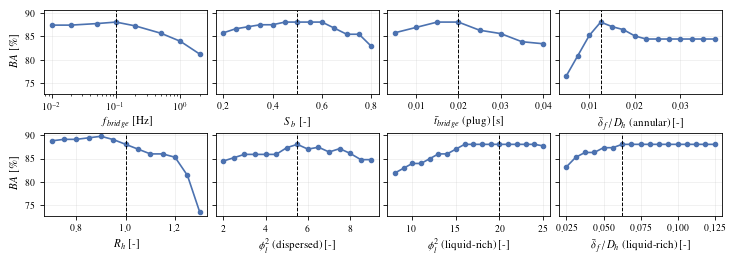

In [14]:
df_sweep = pd.read_csv(results_path / 'sensitivity_thresholds.csv')

SHORT_LABELS = {
    'f_bridge_hz': r'$f_{bridge}$ [Hz]',
    'bubble_share_min': r'$S_b$ [-]',
    'plug_min_duration': r'$\bar t_{bridge}$ (plug) [s]',
    'plug_min_f_liquid': r'$f_{liquid}$ (plug) [-]',
    'annular_max_mean_rel': r'$\bar\delta_f/D_h$ (annular) [-]',
    'annular_max_std_rel': r'$\sigma_f/D_h$ (annular) [-]',
    'dispersed_min_peaks': r'$N_p$ [-]',
    'dispersed_min_mean_rel': r'$\bar\delta_f/D_h$ (agitated) [-]',
    'dispersed_min_jump': r'$J$ [-]',
    'dispersed_min_detected': r'Detected fraction [-]',
    'agitated_min_homog_ratio': r'$R_h$ [-]',
    'dispersed_max_phi2': r'$\phi_l^2$ (dispersed) [-]',
    'liquid_rich_max_phi2': r'$\phi_l^2$ (liquid-rich) [-]',
    'liquid_rich_max_film_rel': r'$\bar\delta_f/D_h$ (liquid-rich) [-]',
}

# Condensed: one threshold per decision of the criterion (family, bubbly, plug, annular, mixed flow,
# dispersed/churn, liquid-rich film); the full sweep is in CRITERIA_VERSION/processed_v2
MAIN_THRESHOLDS = ['f_bridge_hz', 'bubble_share_min', 'plug_min_duration', 'annular_max_mean_rel',
                   'agitated_min_homog_ratio', 'dispersed_max_phi2', 'liquid_rich_max_phi2', 'liquid_rich_max_film_rel']
df_main = df_sweep[df_sweep['parameter'].isin(MAIN_THRESHOLDS)]
df_main = df_main.set_index('parameter').loc[MAIN_THRESHOLDS].reset_index()
fig = sweep_figure(df_main, P, SHORT_LABELS, width=TEXT_W, row_height=1.25, label_size=8, tick_size=7,
                   ylabel=r'$BA$ [\%]')
save(fig, 'fig24_sensitivity_thresholds')
display(fig)

## Reynolds number distribution

Distribution of the liquid, gas and two-phase Reynolds numbers of the 157 runs, at column width (not numbered: not yet in the paper). $Re_l = G_l d/\mu_l$ and $Re_g = G_g d/\mu_g$ (each phase flowing alone), and $Re_{tp} = G d/\mu_h$ with the McAdams viscosity, as in the pressure features (`two_phase_state`: gas mass flux with the density at the orifice meter; properties at the test-section pressure and the water temperature). The values per run are saved to `reynolds_numbers.csv`.

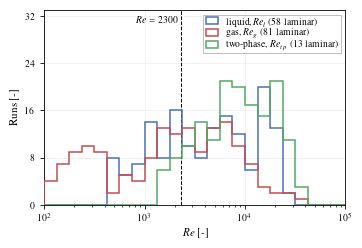

,Re_l,Re_g,Re_tp
count,157.0,157.0,157.0
mean,6866.0,4043.0,10909.0
std,6627.0,5361.0,8006.0
min,435.0,122.0,1334.0
25%,1533.0,461.0,4423.0
50%,4631.0,2137.0,8290.0
75%,10205.0,5607.0,16078.0
max,29361.0,31918.0,32422.0


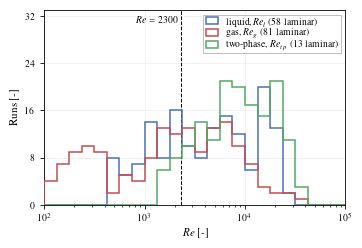

In [15]:
from src.pressure_features import two_phase_state

state = two_phase_state(df_eval)

reynolds = pd.DataFrame({
    'run_id': state['run_id'].to_numpy(),
    'reference_pattern': df_eval['reduced_pattern'].to_numpy(),
    'Re_l': state['Re_l'].to_numpy(),
    'Re_g': state['Re_g'].to_numpy(),
    'Re_tp': state['Re_tp'].to_numpy(),
})
reynolds.to_csv(out / 'reynolds_numbers.csv', index=False)

RE_LAMINAR = 2300
RE_SERIES = [('Re_l', 'liquid, $Re_l$', '#4C72B0'), ('Re_g', 'gas, $Re_g$', '#C44E52'), ('Re_tp', 'two-phase, $Re_{tp}$', '#55A868')]

lo = np.floor(np.log10(reynolds[['Re_l', 'Re_g', 'Re_tp']].min().min()))
hi = np.ceil(np.log10(reynolds[['Re_l', 'Re_g', 'Re_tp']].max().max()))
bins = np.logspace(lo, hi, int(8 * (hi - lo)) + 1)

fig, ax = plt.subplots(figsize=(COL_W, BOX_H))

for column, label, color in RE_SERIES:
    n_laminar = int((reynolds[column] < RE_LAMINAR).sum())
    ax.hist(reynolds[column], bins=bins, histtype='step', linewidth=1.1, color=color,
            label=f'{label} ({n_laminar} laminar)', zorder=3)

ax.axvline(RE_LAMINAR, color='k', linestyle='--', linewidth=0.7, zorder=2)
ax.set_xscale('log')
ax.set_xlim(bins[0], 10 ** (np.ceil(2 * np.log10(reynolds[['Re_l', 'Re_g', 'Re_tp']].max().max())) / 2))
ax.set_ylim(0, 1.5 * ax.get_ylim()[1])   # room for the legend above the bars
ax.text(RE_LAMINAR * 0.9, 0.97, r'$Re = 2300$', transform=ax.get_xaxis_transform(), va='top', ha='right', fontsize=7)
ax.set_xlabel(r'$Re$ [-]')
ax.set_ylabel('Runs [-]')
ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
ax.grid(alpha=0.3, zorder=0)
legend = ax.legend(loc='upper right', frameon=True, framealpha=0.9, edgecolor='0.6', fancybox=False,
                   handlelength=1.2, borderpad=0.3, labelspacing=0.25)
legend.get_frame().set_linewidth(0.5)

save(fig, 'reynolds_distribution')
display(fig)

reynolds[['Re_l', 'Re_g', 'Re_tp']].describe().round(0)

## Checks

In [16]:
# The figures use the classification of CRITERIA_VERSION unchanged
balanced, agreement = balanced_accuracy(features['reduced_pattern'], features['objective_pattern'], OBJECTIVE_PATTERNS)

print(f'agreement {100 * agreement:.1f} %, balanced accuracy {100 * balanced:.1f} %')
reported = pd.read_csv(criteria_path / 'variant_comparison_criterion.csv', index_col=0).loc['processed_v2']
assert np.isclose(agreement, reported['agreement']) and np.isclose(balanced, reported['balanced_accuracy'])

print(f'{len(saved)} files in {out}:')
for name in saved:
    print('  ', name)

agreement 87.9 %, balanced accuracy 88.1 %
39 files in C:\Users\fernando\Downloads\projects\phd_paper\data\gold_layer\objective_criteria_11\paper_figures_1:
   fig06_tube_thickness_before_treatment.pdf
   fig07_tube_thickness_after_treatment.pdf
   fig08a_mixer_wave_before.pdf
   fig08b_mixer_wave_after.pdf
   fig09_evaluated_region.pdf
   fig11_decision_tree.tex
   fig11_decision_tree.pdf
   fig12a_profile_bubbly_run65.pdf
   fig12b_profile_bubbly_run59.pdf
   fig13a_profile_plug_run33.pdf
   fig13b_profile_plug_run28.pdf
   fig14a_profile_slug_run67.pdf
   fig14b_profile_slug_run56.pdf
   fig15a_profile_dispersed_run8.pdf
   fig15b_profile_dispersed_run9.pdf
   fig16a_profile_wavy_run45.pdf
   fig16b_profile_wavy_run44.pdf
   fig17a_profile_churn_run93.pdf
   fig17b_profile_churn_liquid_rich_run1.pdf
   fig17c_profile_annular_run85.pdf
   fig18a_bottom_film_by_pattern.pdf
   fig18b_bottom_film_separated_zoom.pdf
   fig19a_kde_bubbly.pdf
   fig19b_kde_plug.pdf
   fig19c_kde_slug.pdf
 